#### Load Packages

In [1]:
#Basic
import pandas as pd
import numpy as np

#Chem
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Modeling Training and Evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (make_scorer, matthews_corrcoef, classification_report, roc_curve, auc, 
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, 
                             ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC


# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147 
np.random.seed(RANDOM_SEED)

#### Load Dataset

In [3]:
url = "https://zenodo.org/records/11062077/files/dataset_final.csv?download=1"
df = pd.read_csv(url)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

                          name    CID         CAS  \
0             Ethanedioic acid    971    144-62-7   
1                  Para-cymene   7463     99-87-6   
2                   Kieselguhr  24261  61790-53-2   
3                 Benzoic acid    243     65-85-0   
4  Tetradifon (Ref: ENT 23737)   8305    116-29-0   

                                    SMILES  source  year toxicity_type  \
0                             O=C(O)C(=O)O  ECOTOX  1832       Contact   
1                         Cc1ccc(C(C)C)cc1    BPDB  1833         Other   
2                                 O=[Si]=O  ECOTOX  1833       Contact   
3                           O=C(O)c1ccccc1  ECOTOX  1833       Contact   
4  O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl    PPDB  1836          Oral   

   herbicide  fungicide  insecticide  other_agrochemical  label  ppdb_level  
0          0          0            0                   0      0           0  
1          0          0            0                   1      0           1  
2 

Shape: (1035, 13)
Columns: ['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']


### EDA
(1) Creating Features

(2) Correlation Analysis

(3) Tanimoto Similarity

In [4]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#find the number of bits on for each MorganFP


#calculte the mean and sd of the tanimoto similarities for the three classes

#create two filtered dataframes for nontoxic and toxic

nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))

#fingerprint_df.head()

Dataframe of fingerprints shape: (1035, 2048)
177 171


In [5]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


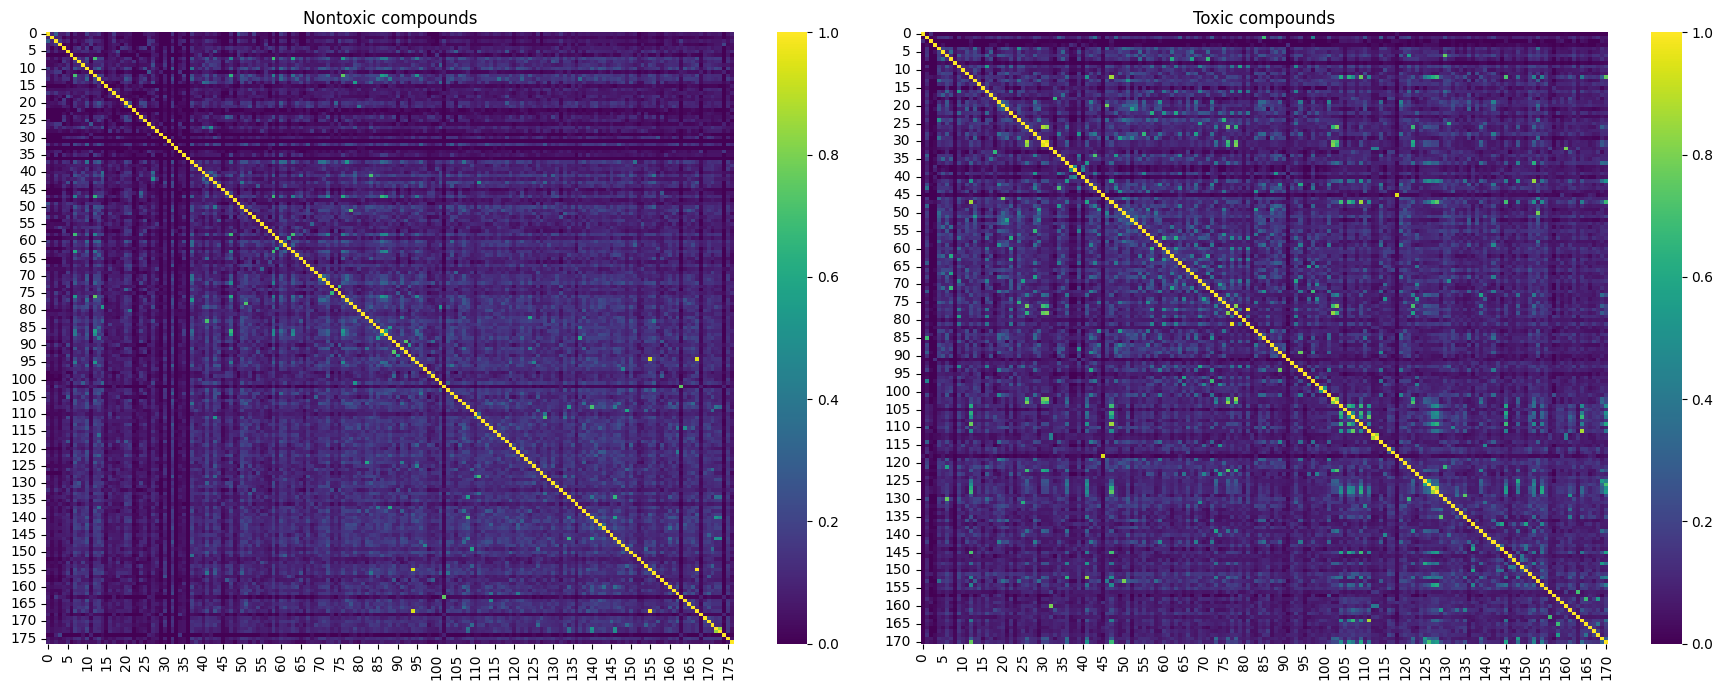

In [6]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule']) 
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

### Train/Test Split
The ApisTox dataset comes with three prepared train-test splits to encourage benchmarking and collaboration with the dataset. The Train/Test is split 80-20. The splits were prepared with different validation goals in mind: two are interpolative and one is extrapolative. Interpolative splits validate predictive performance inside the domain of the dataset. Extrapolative splits aim to verify out-of-domain generalization of models to structurally novel compounds. All of the details below are summarized from the 2025 ApisTox publication: 
- **Stratified Random Split**

    Interpolative. Data is stratified by binary toxic and nontoxic class labels. This split may be prone to some data leakage which artificially increases test score, as this split is susceptible to clustering in chemical space (some very similar compounds make their way into both train and test sets). Scikit-learn used to prepare split.

- **Maximum Diversity Split (Max-Min Split)**

    Interpolative. The 'Maximum Diversity Picking Algorithm' is used to select test molecules so that the sum of the distances in the test set is maximized. Dice similarities with 1024 bit ECFP4 fingerprints, and the 'DeepChem' package were used to prepare this split.

- **Time Split (Chronological Split by Pubchem Date)**

    Extrapolative. The newest molecules (determined by date first appearing in bee literature, source: PubChem) are put into the test set. The assumption is that new substances are introduced over time. This is seen as an alternative to the 'scaffold split' in which new chemical 'scaffolds' (chemical moieites) are introduced over time. Pandas used to prepare split.


In [4]:
### Import All Pre-Made ApisTox Train-Test Splits ###
random_train = pd.read_csv("https://zenodo.org/records/11062077/files/random_train.csv?download=1")
random_test = pd.read_csv("https://zenodo.org/records/11062077/files/random_test.csv?download=1")
time_train = pd.read_csv("https://zenodo.org/records/11062077/files/time_train.csv?download=1")
time_test = pd.read_csv("https://zenodo.org/records/11062077/files/time_test.csv?download=1")
maxmin_train = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_train.csv?download=1")
maxmin_test = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_test.csv?download=1")

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


In [5]:
#set morgan fp generating params
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

In [6]:
# Define a function to add fingerprints to each of these datasets.
def add_fp(dataframe):
    if dataframe.shape[1] < 1000: #use to not accidentally add columns twice

        PandasTools.AddMoleculeColumnToFrame(dataframe, smilesCol='SMILES', molCol='molecule')

        morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    
        # Generate fingerprints for all molecules
        fingerprints = []
        for mol in dataframe['molecule']:
            fp = morgan_gen.GetFingerprint(mol)
            fingerprints.append(fp.ToList())

        # Convert to DataFrame with indexed column names
        fp_columns = [f'Morgan_bit_{i}' for i in range(2048)]
        fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=dataframe.index)
        
        dataframe = pd.concat([dataframe, fingerprint_df], axis=1)
        
        return dataframe
    else:
        return dataframe

In [7]:
#apply fingerprint function to each ApisTox split 
#splits = [random_train, random_test, time_train, time_test, maxmin_train, maxmin_test]
random_train = add_fp(random_train)
random_test = add_fp(random_test)
time_train = add_fp(time_train)
time_test = add_fp(time_test)
maxmin_train = add_fp(maxmin_train)
maxmin_test = add_fp(maxmin_test)

In [17]:
random_train.head()

                                                name       CID          CAS  \
0                  Mepiquat chloride (Ref: BAS 083W)     62781   24307-26-4   
1  N-(2,6-Dichlorophenyl)-5-ethoxy-7-fluoro-[1,2,...   3081304  145701-21-9   
2                      (Acetato-kappaO)phenylmercury  16682730      62-38-4   
3                         As,As-Dimethylarsinic acid      2513      75-60-5   
4                                      Tritosulfuron  11657899  142469-14-5   

                                              SMILES  source  year  \
0                              C[N+]1(C)CCCCC1.[Cl-]    PPDB  1980   
1      CCOc1nc(F)cc2nc(S(=O)(=O)Nc3c(Cl)cccc3Cl)nn12  ECOTOX  2000   
2                                CC(=O)O[Hg]c1ccccc1  ECOTOX  1891   
3                                      C[As](C)(=O)O  ECOTOX  1901   
4  COc1nc(NC(=O)NS(=O)(=O)c2ccccc2C(F)(F)F)nc(C(F...    PPDB  2007   

  toxicity_type  herbicide  fungicide  insecticide  ...  Morgan_bit_2037  \
0       Contact          0  

In [8]:
from sklearn.feature_selection import VarianceThreshold

random_vt = VarianceThreshold(0)
maxmin_vt = VarianceThreshold(0)
time_vt = VarianceThreshold(0)

#define initial features
TARGET = "ppdb_level"
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]

random_vt.fit(random_train[RANDOM_FEATURES])
random_selected_cols = random_train.columns[random_vt.get_support(indices=True)]
random_train_filtered = random_train[random_selected_cols]
random_test_filtered = random_test[random_selected_cols]
RANDOM_FEATURES = [col for col in random_train_filtered.columns if col.startswith("Morgan_bit_")]
#random_train_filtered.head()

maxmin_vt.fit(maxmin_train[MAXMIN_FEATURES])
maxmin_selected_cols = maxmin_train.columns[maxmin_vt.get_support(indices=True)]
maxmin_train_filtered = maxmin_train[maxmin_selected_cols]
maxmin_test_filtered = maxmin_test[maxmin_selected_cols]
MAXMIN_FEATURES = [col for col in maxmin_train_filtered.columns if col.startswith("Morgan_bit_")]

time_vt.fit(time_train[TIME_FEATURES])
time_selected_cols = time_train.columns[time_vt.get_support(indices=True)]
time_train_filtered = time_train[time_selected_cols]
time_test_filtered = time_test[time_selected_cols]
TIME_FEATURES = [col for col in time_train_filtered.columns if col.startswith("Morgan_bit_")]
#random_train_filtered = pd.DataFrame(vt.fit_transform(random_train[RANDOM_FEATURES]),columns=RANDOM_FEATURES)
#random_test_filtered = pd.DataFrame(vt.transform(random_test[RANDOM_FEATURES]),columns=RANDOM_FEATURES)

#maxmin_train_filtered = pd.DataFrame(vt.fit_transform(maxmin_train[MAXMIN_FEATURES]),columns=MAXMIN_FEATURES)
#maxmin_test_filtered = pd.DataFrame(vt.transform(maxmin_test[MAXMIN_FEATURES]),columns=MAXMIN_FEATURES)

#time_train_filtered = pd.DataFrame(vt.fit_transform(time_train[TIME_FEATURES]),columns=TIME_FEATURES)
#time_test_filtered = pd.DataFrame(vt.transform(time_test[TIME_FEATURES]),columns=TIME_FEATURES)

,threshold,0


,threshold,0


,threshold,0


In [10]:
random_train[RANDOM_FEATURES].head()

   Morgan_bit_0  Morgan_bit_2  Morgan_bit_4  Morgan_bit_5  Morgan_bit_6  \
0             0             1             0             0             0   
1             0             0             0             0             0   
2             0             0             0             0             0   
3             0             0             0             0             0   
4             0             0             0             0             0   

   Morgan_bit_7  Morgan_bit_9  Morgan_bit_10  Morgan_bit_11  Morgan_bit_12  \
0             0             0              0              0              0   
1             0             0              0              0              0   
2             0             0              0              0              0   
3             0             0              0              0              0   
4             0             0              0              0              0   

   ...  Morgan_bit_2023  Morgan_bit_2024  Morgan_bit_2025  Morgan_bit_2026  \
0 

In [12]:
#define features (per split) and target and drop features with zero variance

#define initial features
TARGET = "ppdb_level"
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]

# Find and print the number of all zero-variance features by split
random_redundant_features = [RANDOM_FEATURES for RANDOM_FEATURES in random_train.columns if random_train[RANDOM_FEATURES].nunique() == 1]
maxmin_redundant_features = [MAXMIN_FEATURES for MAXMIN_FEATURES in maxmin_train.columns if maxmin_train[MAXMIN_FEATURES].nunique() == 1]
time_redundant_features = [TIME_FEATURES for TIME_FEATURES in time_train.columns if time_train[TIME_FEATURES].nunique() == 1]
print(f'Number of Zero Variance Features by Split -- Random: {len(random_redundant_features)}, MaxMin: {len(maxmin_redundant_features)}, Time: {len(time_redundant_features)}')

# Dropping Features with Zero Variance -- w/ print statements to confirm
print(f'\n\n Random Split Shape Before Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')
random_train = random_train.drop(columns=random_redundant_features)
random_test = random_test.drop(columns=random_redundant_features)
print(f'Random Split Shape After Drop -- Train: {random_train.shape} -- Test: {random_test.shape}')

print(f'MaxMin Split Shape Before Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')
maxmin_train = maxmin_train.drop(columns=maxmin_redundant_features)
maxmin_test = maxmin_test.drop(columns=maxmin_redundant_features)
print(f'MaxMin Split Shape After Drop -- Train: {maxmin_train.shape} -- Test: {maxmin_test.shape}')

print(f'Time Split Shape Before Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')
time_train = time_train.drop(columns=time_redundant_features)
time_test = time_test.drop(columns=time_redundant_features)
print(f'Time Split Shape After Drop -- Train: {time_train.shape} -- Test: {time_test.shape}')

#update features by column -- w/ print statements to confirm
print(f'\n\n Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')
RANDOM_FEATURES = [col for col in random_train.columns if col.startswith("Morgan_bit_")]
MAXMIN_FEATURES = [col for col in maxmin_train.columns if col.startswith("Morgan_bit_")]
TIME_FEATURES = [col for col in time_train.columns if col.startswith("Morgan_bit_")]
print(f'Updated Number of Features by Split -- Random: {len(RANDOM_FEATURES)}, MaxMin: {len(MAXMIN_FEATURES)}, Time: {len(TIME_FEATURES)}')

Number of Zero Variance Features by Split -- Random: 0, MaxMin: 0, Time: 0


 Random Split Shape Before Drop -- Train: (828, 1962) -- Test: (207, 1962)
Random Split Shape After Drop -- Train: (828, 1962) -- Test: (207, 1962)
MaxMin Split Shape Before Drop -- Train: (828, 1928) -- Test: (207, 1928)
MaxMin Split Shape After Drop -- Train: (828, 1928) -- Test: (207, 1928)
Time Split Shape Before Drop -- Train: (828, 1921) -- Test: (207, 1921)
Time Split Shape After Drop -- Train: (828, 1921) -- Test: (207, 1921)


 Number of Features by Split -- Random: 1948, MaxMin: 1914, Time: 1907
Updated Number of Features by Split -- Random: 1948, MaxMin: 1914, Time: 1907


In [11]:
# Create Dictionary Containing Error Metrics 
def get_regression_metrics(model, dataframe, X, y_true):
    """
    Get a dictionary w/ metrics: 'model' is sklearn model w/ predict method,
    'X' is dataframe(FEATURES), 'y' is dataframe(TARGET)
    """
    y_pred = model.predict(X)

    f1 = f1_score(y_true, y_pred, average= 'weighted', zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0) # Add zero_division=0 to handle cases with no positive predictions
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    #confusion = confusion_matrix(y_true, model.predict(X), normalize='true')
    #report = classification_report(y_true, y_pred, zero_division=0)
    # ^ bring these back later

    metrics_dict = {
        'F1': f1,
        'MCC': mcc,
        'accuracy': acc,
        'precision':  prec, 
        'recall': rec,
      #  'confusion matrix': confusion,
      #  'classification_report': report
      # bring these back ater ^
    }

    return metrics_dict

Model Testing

In [ ]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED,
    C=1,
    gamma='scale'
)


In [16]:
from sklearn.base import clone
# Fit independent models for each split

random_svc = clone(svm).fit(random_train[RANDOM_FEATURES], random_train[TARGET])
maxmin_svc = clone(svm).fit(maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
time_svc = clone(svm).fit(time_train[TIME_FEATURES], maxmin_train[TARGET])

#if creating loop
#create a list of dummy models 
svc_models = [
    ('random', random_svc),
    ('maxmin', maxmin_svc),
    ('time', time_svc),
]

# initialize dictionaries for error metrics
svc_results_test = {}
svc_results_train = {}

svc_results_test['random'] = get_regression_metrics(random_svc, random_test_filtered, random_test[RANDOM_FEATURES], random_test[TARGET])
svc_results_train['random'] = get_regression_metrics(random_svc, random_train_filtered, random_train[RANDOM_FEATURES], random_train[TARGET])
svc_results_test['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_test_filtered, maxmin_test[MAXMIN_FEATURES], maxmin_test[TARGET])
svc_results_train['maxmin'] = get_regression_metrics(maxmin_svc, maxmin_train_filtered, maxmin_train[MAXMIN_FEATURES], maxmin_train[TARGET])
svc_results_test['time'] = get_regression_metrics(time_svc, time_test_filtered, time_test[TIME_FEATURES], time_test[TARGET])
svc_results_train['time'] = get_regression_metrics(time_svc, time_train_filtered, time_train[TIME_FEATURES], time_train[TARGET])


In [17]:
# Print the metrics for all models
print("Dummy Results - All Splits -  Test and Train Sets")

for regressor_name, metrics in svc_results_train.items():
    print(f"\n\n Train Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

for regressor_name, metrics in svc_results_test.items():
    print(f"\n\n Test Set -- {regressor_name} split:")
    for metric, value in metrics.items():
        print(f'{metric}:{value:.3f}', end=' ')

Dummy Results - All Splits -  Test and Train Sets


 Train Set -- random split:
F1:0.884 MCC:0.801 accuracy:0.880 precision:0.906 recall:0.880 

 Train Set -- maxmin split:
F1:0.903 MCC:0.824 accuracy:0.901 precision:0.915 recall:0.901 

 Train Set -- time split:
F1:0.448 MCC:-0.007 accuracy:0.419 precision:0.492 recall:0.419 

 Test Set -- random split:
F1:0.693 MCC:0.400 accuracy:0.676 precision:0.729 recall:0.676 

 Test Set -- maxmin split:
F1:0.632 MCC:0.238 accuracy:0.686 precision:0.637 recall:0.686 

 Test Set -- time split:
F1:0.550 MCC:-0.007 accuracy:0.604 precision:0.520 recall:0.604 

Text(0.5, 0.98, 'SVC (RGF) Model Confusion Matrices -- All Splits -- Test and Train Sets')

<Axes: >

Text(0.5, 1.0, 'Random Train')

Text(158.22222222222223, 0.5, 'Real')

Text(0.5, 500.7222222222223, 'Model')

<Axes: >

... (135 outputs left out)

<Axes: title={'center': 'Time Test'}>

Text(0.5, 1.0, 'Time Test')

Text(978.81045751634, 0.5, 'Real')

Text(0.5, 80.7222222222222, 'Model')

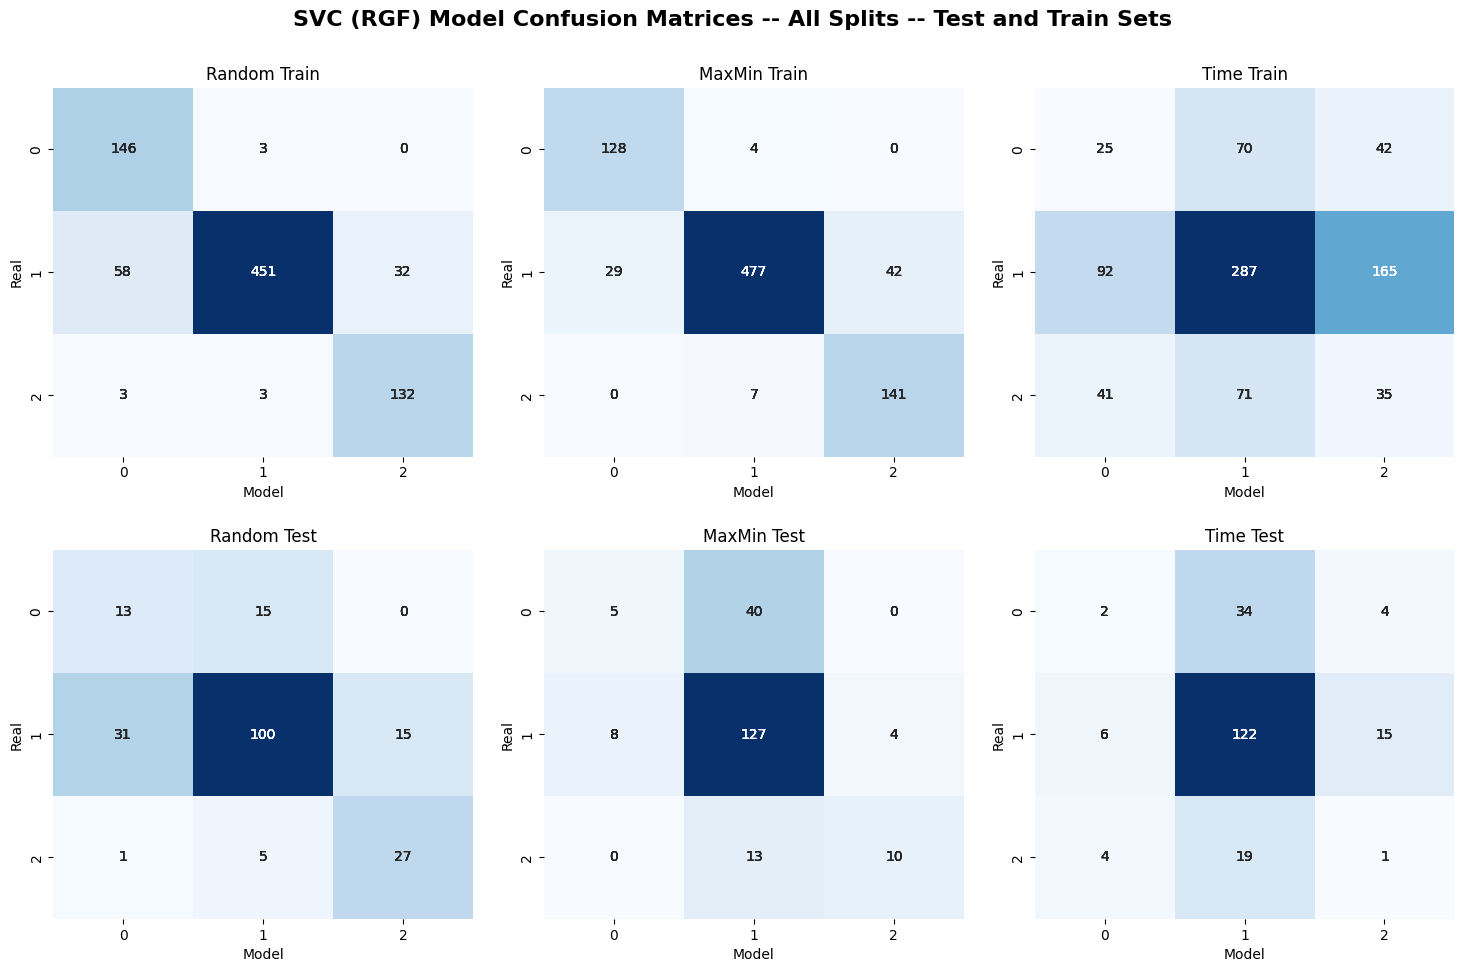

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('SVC (RGF) Model Confusion Matrices -- All Splits -- Test and Train Sets', fontsize=16, fontweight='bold')

descriptors_to_plot = ['Random Train', 'MaxMin Train', 'Time Train',
                        'Random Test', 'MaxMin Test', 'Time Test']

for i in enumerate(descriptors_to_plot):
    for i, descriptor in enumerate(descriptors_to_plot):
        row = i // 3
        col = i % 3

        if descriptor == "Random Train":
            cm = confusion_matrix(random_train[TARGET], random_svc.predict(random_train[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Train":
            cm = confusion_matrix(maxmin_train[TARGET], maxmin_svc.predict(maxmin_train[MAXMIN_FEATURES]))
        elif descriptor == "Time Train":
            cm = confusion_matrix(time_train[TARGET], time_svc.predict(time_train[TIME_FEATURES]))
        elif descriptor == "Random Test":
            cm = confusion_matrix(random_test[TARGET], random_svc.predict(random_test[RANDOM_FEATURES]))
        elif descriptor == "MaxMin Test":
            cm = confusion_matrix(maxmin_test[TARGET], maxmin_svc.predict(maxmin_test[MAXMIN_FEATURES]))
        elif descriptor == "Time Test":
            cm = confusion_matrix(time_test[TARGET], time_svc.predict(time_test[TIME_FEATURES]))

        sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', ax=axes[row, col], cbar=False)
        axes[row, col].set_title(descriptor)
        axes[row, col].set_ylabel("Real")
        axes[row, col].set_xlabel("Model")
    col = i % 3

#cm1 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')
#cm2 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')
#cm3 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')
#cm4 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')
#cm5 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')
#cm6 = confusion_matrix(random_train[TARGET], random_dummy.predict(random_train[FEATURES]), normalize='true')


#fig,ax = plt.subplots()
#sns.heatmap(cm1, annot=True, fmt='.2f', cmap='Blues')
#sns.heatmap(cm2, annot=True, fmt='.2f', cmap='Blues')
#sns.heatmap(cm3, annot=True, fmt='.2f', cmap='Blues')
#sns.heatmap(cm4, annot=True, fmt='.2f', cmap='Blues')
#sns.heatmap(cm5, annot=True, fmt='.2f', cmap='Blues')
#sns.heatmap(cm6, annot=True, fmt='.2f', cmap='Blues')

#ax.set_ylabel("Real")
#ax.set_xlabel("Model")
plt.tight_layout(pad=2)
plt.show()

SVC (using RGF Kernel)

Hyperparameter Tuning

C is the Controls decision boundary flexibility
    Small value (0.1) gives a smoother boundary
    Large Value (100) gives a More complex boundary and more risk of overfitting

Gamma - Controls how far a molecule's influence extends
    small (0.001) gives smooth global boundaries
    large (1) gives very local boundaries and can overfit badly

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
# cross validation split
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

In [6]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_SEED
)

svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, "scale"]
}

grid_svm = GridSearchCV(
    svm,
    svm_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_svm.fit(fingerprint_df, df['ppdb_level'])

print(grid_svm.best_params_)
print(grid_svm.best_score_)

,estimator,SVC(class_wei...om_state=1147)
,param_grid,"{'C': [0.1, 1, ...], 'gamma': [0.001, 0.01, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


{'C': 1, 'gamma': 'scale'}
0.5877982451948782


SVC Confusion Matrix

<Axes: >

Text(50.722222222222214, 0.5, 'Real')

Text(0.5, 23.52222222222222, 'Model')

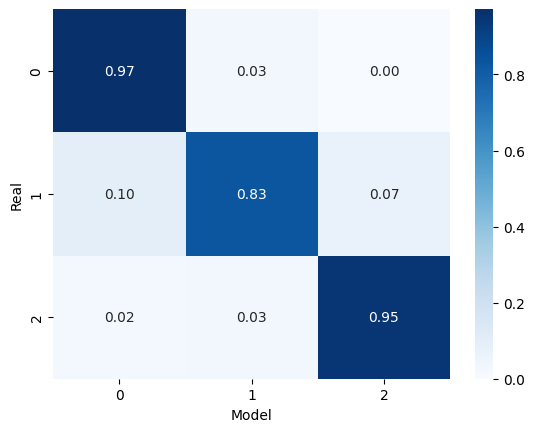

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(df['ppdb_level'], grid_svm.predict(fingerprint_df), normalize='true')

fig,ax = plt.subplots()
sns.heatmap(
    cm,
    annot=True,
    fmt='.2f',
    cmap='Blues'
)
ax.set_ylabel("Real")
ax.set_xlabel("Model")

In [19]:
from sklearn.metrics import classification_report
classification_report(df['ppdb_level'], grid_svm.predict(fingerprint_df),output_dict=True)

{'0': {'precision': 0.7020408163265306,
  'recall': 0.9717514124293786,
  'f1-score': 0.8151658767772512,
  'support': 177.0},
 '1': {'precision': 0.9827882960413081,
  'recall': 0.8311499272197962,
  'f1-score': 0.9006309148264984,
  'support': 687.0},
 '2': {'precision': 0.7751196172248804,
  'recall': 0.9473684210526315,
  'f1-score': 0.8526315789473684,
  'support': 171.0},
 'accuracy': 0.8743961352657005,
 'macro avg': {'precision': 0.8199829098642398,
  'recall': 0.9167565869006021,
  'f1-score': 0.8561427901837059,
  'support': 1035.0},
 'weighted avg': {'precision': 0.9004659308363566,
  'recall': 0.8743961352657005,
  'f1-score': 0.8780848296380462,
  'support': 1035.0}}

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lg = LogisticRegression(
    class_weight="balanced",
    max_iter=5000
)

lg_param_grid = {
    "C": [0.1, 1, 10, 100],
    "l1_ratio": [0, 0.25, 0.5, 0.75, 1]
}

grid_lg = GridSearchCV(
    lg,
    lg_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_lg.fit(fingerprint_df, df['ppdb_level'])

print(grid_lg.best_params_)
print(grid_lg.best_score_)

c:\Users\pprat\.gemini\antigravity-ide\scratch\CHE1147\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


,estimator,LogisticRegre...max_iter=5000)
,param_grid,"{'C': [0.1, 1, ...], 'l1_ratio': [0, 0.25, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


{'C': 0.1, 'l1_ratio': 0}
0.5802200111274375


Random Forest Classifier

In [35]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced"
)

rfc_param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_features": [int, float, "sqrt", "log2", None]
}

grid_rfc = GridSearchCV(
    rfc,
    rfc_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_rfc.fit(fingerprint_df, df['ppdb_level'])

print(grid_rfc.best_params_)
print(grid_rfc.best_score_)

c:\Users\pprat\.gemini\antigravity-ide\scratch\CHE1147\.venv\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
30 fits failed out of a total of 75.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\pprat\.gemini\antigravity-ide\scratch\CHE1147\.venv\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\pprat\.gemini\antigravity-ide\scratch\CHE1147\.venv\lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
  File "c:\Users\pprat\.gemini\antigravity-ide\scratch\CHE1147\.venv\lib\site-

,estimator,RandomForestC...stimators=500)
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_features': [<class 'int'>, <class 'float'>, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,500


{'criterion': 'gini', 'max_features': None}
0.5798816792677801


### Model Training

#### Training Dummy/Baseline Model

#### Training Random Forest Model
Hyperparameters are tuned using 5-fold cross-validation, model with highest Matthews Correlation Coefficient (MCC) is selected.

#### Train Graph Kernel Model

Hyperparameters are tuned using 5-fold cross-validation, model with highest MCC is selected.

### Model Evaluation
For all models, the following are reported:
Macro F1, AUC, MCC, precision, recall, balanced accuracy, per-class precision and recall. Confusion matrices and ROC are also generated. 

### Further Data Analysis and Considerations
Addressing class imbalance: partial undersampling of majority class (apply to training portion of each cross-validation fold), class weighting.

Precision vs. Recall Tradeoff: affected by cutoff value used for logistic regression (sigmoid parameter). Will need to see if this parameter is tunable for the multiclass version. This parameter can be related to the FP/FN ratio, which can be tuned to suit use-cases/goals which differ in being more or less conservative in their predictions of compound toxicity.

| FP/FN (ratio) | plain language | drawback |
|-|-|-|
| higher | Agrochemicals that are o.k. for bees are recommended as 'do not use' | limits design space of agrochemicals|
| low | Agrochemicals which are harmful for bees are recommended as 'o.k. to use' | harms bees |